# Analisis Time Series Pasar Saham & Keuangan (2020–2026)
**Midterm Project — Visualisasi Data (CAK4XBB3)**
**Kelompok Cihuy**

| No | Nama | NIM | Bagian |
|----|------|-----|--------|
| 1 | Adhyatma Chrysostomos Davu | 103012340479 | Data & kerangka notebook |
| 2 | Raffa Anung El Haqqi | 103012300163 | Line Plot & Area Plot |
| 3 | Tristan Satria Perdana Hermawan | 103012300253 | Multiple Time Series & Seasonal/Heatmap |
| 4 | Naufal Rafif Hidayat | 103012300403 | Analisis Tren |
| 5 | Ahmad Naufal Ramadhan | 103012300239 | Kesimpulan, Deklarasi AI, Daftar Pustaka |

**Sumber data:** Yahoo Finance — https://finance.yahoo.com (diunduh dengan library `yfinance`)

## 1. Pendahuluan
*(Davu)*

Pasar keuangan Indonesia dan global mengalami beberapa guncangan besar sejak 2020: crash pandemi COVID-19 (Maret 2020), lonjakan inflasi dan kenaikan suku bunga global (2022), serta reli aset kripto dan emas pada 2024–2025. Data harga harian adalah contoh time series nyata yang mengandung **tren**, **pola musiman/periodik**, **siklus**, dan **noise**, sehingga cocok untuk dianalisis dengan teknik visualisasi time series.

**Tujuan analisis:**
1. Melihat pola pergerakan utama IHSG dan aset keuangan lain selama 2020–2026.
2. Membandingkan kinerja beberapa kelas aset (indeks saham, saham bank, kripto, emas, kurs) dalam satu grafik.
3. Mencari pola musiman/periodik pada imbal hasil (return) harian.
4. Mengidentifikasi tren jangka pendek dan panjang dengan Moving Average dan fitting model.

## 2. Dataset
*(Davu)*

### 2.1 Sumber data
Data diambil dari **Yahoo Finance** (https://finance.yahoo.com) menggunakan library Python `yfinance`. Data berupa harga harian (Open, High, Low, Close, Volume) periode **1 Januari 2020 – 31 Oktober 2026** untuk 9 aset dari 5 kategori:

| Kategori | Ticker Yahoo | Nama di notebook | Mata uang |
|----------|--------------|------------------|-----------|
| Indeks | `^JKSE` | IHSG | IDR (poin) |
| Indeks | `^GSPC` | S&P 500 | USD (poin) |
| Saham Bank | `BBCA.JK` | BBCA | IDR |
| Saham Bank | `BBRI.JK` | BBRI | IDR |
| Saham Bank | `BMRI.JK` | BMRI | IDR |
| Saham Bank | `BBNI.JK` | BBNI | IDR |
| Kripto | `BTC-USD` | Bitcoin | USD |
| Komoditas | `GC=F` | Emas (futures) | USD/troy ounce |
| Kurs | `IDR=X` | USD/IDR | IDR per 1 USD |

Harga sudah **disesuaikan (adjusted)** terhadap stock split dan dividen (`auto_adjust=True`).

Script unduhan: [`data/download_data.py`](data/download_data.py). Notebook ini membaca file CSV hasil unduhan agar hasil analisis **reproducible** (tidak berubah setiap kali dijalankan). Set `DOWNLOAD_ULANG = True` untuk mengunduh ulang dari Yahoo Finance.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

pd.set_option("display.float_format", "{:,.2f}".format)

# Gaya grafik bersama untuk SEMUA anggota (biar konsisten)
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

# Palet Okabe-Ito (ramah buta warna, Minggu 1) -> satu warna tetap per aset
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2",
             "#D55E00", "#CC79A7", "#000000", "#999999"]
ASET = ["IHSG", "S&P 500", "BBCA", "BBRI", "BMRI", "BBNI", "Bitcoin", "Emas", "USD/IDR"]
WARNA = dict(zip(ASET, ["#0072B2", "#D55E00", "#009E73", "#56B4E9", "#E69F00",
                        "#CC79A7", "#F0E442", "#999999", "#000000"]))
KATEGORI = {"IHSG": "Indeks", "S&P 500": "Indeks", "BBCA": "Saham Bank", "BBRI": "Saham Bank",
            "BMRI": "Saham Bank", "BBNI": "Saham Bank", "Bitcoin": "Kripto",
            "Emas": "Komoditas", "USD/IDR": "Kurs"}

# Simpan grafik ke folder figures/ untuk laporan & slide
from pathlib import Path
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def simpan(nama):
    plt.savefig(FIG_DIR / f"{nama}.png", dpi=150, bbox_inches="tight")

### 2.2 Load data mentah

In [2]:
DOWNLOAD_ULANG = False   # True = unduh ulang dari Yahoo Finance (butuh internet)

if DOWNLOAD_ULANG:
    import subprocess, sys
    subprocess.run([sys.executable, "data/download_data.py"], check=True)

raw = pd.read_csv("data/raw_yahoo_finance.csv", parse_dates=["Date"])
print("Ukuran data mentah:", raw.shape)
raw.head()

Ukuran data mentah: (15936, 9)


,Date,Ticker,Nama,Kategori,Open,High,Low,Close,Volume
0,2020-01-01,BTC-USD,Bitcoin,Kripto,"7,194.89","7,254.33","7,174.94","7,200.17","18,565,664,997.00"
1,2020-01-01,IDR=X,USD/IDR,Kurs,"13,862.00","13,876.00","13,681.83","13,690.37",0.00
2,2020-01-02,BBCA.JK,BBCA,Saham Bank,"5,505.30","5,575.20","5,492.97","5,501.19","49,445,000.00"
3,2020-01-02,BBNI.JK,BBNI,Saham Bank,"2,878.24","2,878.24","2,841.69","2,841.69","18,602,600.00"
4,2020-01-02,BBRI.JK,BBRI,Saham Bank,"2,674.09","2,680.16","2,649.78","2,680.16","45,886,302.00"


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15936 entries, 0 to 15935
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      15936 non-null  datetime64[us]
 1   Ticker    15936 non-null  str           
 2   Nama      15936 non-null  str           
 3   Kategori  15936 non-null  str           
 4   Open      15936 non-null  float64       
 5   High      15936 non-null  float64       
 6   Low       15936 non-null  float64       
 7   Close     15936 non-null  float64       
 8   Volume    15936 non-null  float64       
dtypes: datetime64[us](1), float64(5), str(3)
memory usage: 1.1 MB


In [4]:
# Rentang waktu & jumlah observasi per aset
ringkas = (raw.groupby(["Kategori", "Nama"])
              .agg(mulai=("Date", "min"), akhir=("Date", "max"), jumlah_hari=("Date", "count"))
              .sort_values("Kategori"))
ringkas

mulai      akhir  jumlah_hari
Kategori   Nama                                      
Indeks     IHSG    2020-01-02 2026-10-30         1645
           S&P 500 2020-01-02 2026-10-30         1717
Komoditas  Emas    2020-01-02 2026-10-30         1720
Kripto     Bitcoin 2020-01-01 2026-10-31         2496
Kurs       USD/IDR 2020-01-01 2026-10-30         1778
Saham Bank BBCA    2020-01-02 2026-10-30         1645
           BBNI    2020-01-02 2026-10-30         1645
           BBRI    2020-01-02 2026-10-30         1645
           BMRI    2020-01-02 2026-10-30         1645

**Catatan:** jumlah hari berbeda karena kalender perdagangan berbeda:
- **Bitcoin** diperdagangkan 7 hari seminggu (termasuk Sabtu–Minggu).
- **Bursa Efek Indonesia** (IHSG & saham bank) libur di hari libur nasional Indonesia (Lebaran, Natal, dll.).
- **S&P 500 & Emas** libur mengikuti kalender Amerika Serikat.
- **Kurs USD/IDR** tersedia setiap hari kerja.

### 2.3 Cek missing values & data cleaning

In [5]:
# Ubah ke format wide: kolom = aset, index = tanggal (kolom waktu jadi index)
close_raw = raw.pivot(index="Date", columns="Nama", values="Close")[ASET]
volume_raw = raw.pivot(index="Date", columns="Nama", values="Volume")[ASET]

missing = pd.DataFrame({
    "missing": close_raw.isna().sum(),
    "persen (%)": close_raw.isna().mean() * 100,
})
missing

,missing,persen (%)
Nama,,
IHSG,851,34.09
S&P 500,779,31.21
BBCA,851,34.09
BBRI,851,34.09
BMRI,851,34.09
BBNI,851,34.09
Bitcoin,0,0.00
Emas,776,31.09
USD/IDR,718,28.77


Langkah cleaning:
1. **Samakan kalender ke hari kerja (Senin–Jumat)** — data Bitcoin di akhir pekan dibuang agar semua aset bisa dibandingkan pada tanggal yang sama.
2. **Isi hari libur bursa dengan harga terakhir (forward fill, maks. 5 hari)** — saat bursa libur, harga tidak berubah, jadi harga penutupan terakhir adalah nilai yang benar, bukan data karangan.
3. **Volume tidak di-forward fill** — hari libur artinya tidak ada transaksi, jadi diisi 0.
4. Kurs `USD/IDR` tidak punya data volume di Yahoo Finance (selalu 0), jadi tidak dipakai untuk analisis volume.

In [6]:
close = close_raw[close_raw.index.dayofweek < 5]   # 1. hanya hari kerja
close = close.dropna(how="all")
close = close.ffill(limit=5).dropna()               # 2. isi libur bursa
volume = volume_raw.reindex(close.index).fillna(0)  # 3. volume hari libur = 0

print("Ukuran setelah cleaning:", close.shape)
print("Periode:", close.index.min().date(), "s/d", close.index.max().date())
print("Sisa missing values:", int(close.isna().sum().sum()))
close.tail()

Ukuran setelah cleaning: (1778, 9)
Periode: 2020-01-02 s/d 2026-10-30
Sisa missing values: 0


Nama,IHSG,S&P 500,BBCA,BBRI,BMRI,BBNI,Bitcoin,Emas,USD/IDR
Date,,,,,,,,,
2026-10-26,"5,373.09","7,676.77","4,940.00","2,910.00","3,910.00","3,470.00","80,006.66","4,038.40","18,081.00"
2026-10-27,"5,266.13","7,722.60","4,900.00","2,900.00","3,870.00","3,310.00","80,805.08","4,074.60","18,144.00"
2026-10-28,"5,282.31","7,743.98","5,275.00","2,920.00","3,840.00","3,350.00","81,267.59","4,051.60","18,139.50"
2026-10-29,"5,098.06","7,720.39","4,940.00","2,810.00","3,720.00","3,240.00","77,775.11","4,031.40","18,065.40"
2026-10-30,"5,057.05","7,580.07","4,980.00","2,800.00","3,720.00","3,320.00","77,198.21","3,898.90","18,070.40"


In [7]:
# Cek duplikat tanggal & urutan waktu
print("Tanggal duplikat :", close.index.duplicated().sum())
print("Index terurut    :", close.index.is_monotonic_increasing)
print("Tipe index       :", type(close.index).__name__)

Tanggal duplikat : 0
Index terurut    : True
Tipe index       : DatetimeIndex


### 2.4 Variabel turunan (dipakai anggota lain)

| Variabel | Isi | Kegunaan |
|----------|-----|----------|
| `close` | Harga penutupan harian (wide) | Line plot, MA, fitting |
| `volume` | Volume transaksi harian (wide) | Area plot |
| `ret` | Return harian (%) = perubahan harga dari hari sebelumnya | Seasonal plot / heatmap, outlier |
| `norm` | Harga dinormalisasi, hari pertama = 100 | Membandingkan banyak aset di satu grafik |
| `close_m` | Harga penutupan akhir bulan | Seasonal plot bulanan |

In [8]:
ret = close.pct_change().dropna() * 100           # return harian dalam persen
norm = close / close.iloc[0] * 100                 # indeks basis 100
close_m = close.resample("ME").last()              # harga akhir bulan

norm.tail(3)

Nama,IHSG,S&P 500,BBCA,BBRI,BMRI,BBNI,Bitcoin,Emas,USD/IDR
Date,,,,,,,,,
2026-10-28,84.07,237.70,95.89,108.95,154.66,117.89,"1,163.38",265.77,132.51
2026-10-29,81.13,236.98,89.80,104.84,149.83,114.02,"1,113.38",264.44,131.97
2026-10-30,80.48,232.67,90.53,104.47,149.83,116.83,"1,105.13",255.75,132.00


### 2.5 Data profiling (statistik deskriptif)

In [9]:
# Statistik deskriptif harga penutupan
close.describe().T

,count,mean,std,min,25%,50%,75%,max
Nama,,,,,,,,
IHSG,"1,778.00","6,690.38",875.39,"3,937.63","6,150.66","6,830.07","7,175.82","9,134.70"
S&P 500,"1,778.00","4,915.98","1,315.27","2,237.40","3,963.62","4,496.51","5,915.74","7,818.93"
BBCA,"1,778.00","7,008.34","1,410.38","3,642.79","5,731.76","7,066.92","8,098.67","9,989.80"
BBRI,"1,778.00","3,306.46",716.24,"1,370.26","2,886.35","3,341.51","3,711.00","5,216.77"
BMRI,"1,778.00","3,572.72","1,180.11","1,251.92","2,453.56","3,870.29","4,455.67","6,002.09"
BBNI,"1,778.00","3,299.22",892.45,"1,189.89","2,586.80","3,584.23","3,930.14","5,026.20"
Bitcoin,"1,778.00","50,469.16","30,907.54","4,970.79","24,149.94","44,635.28","70,105.74","124,752.53"
Emas,"1,778.00","2,482.75",979.85,"1,477.30","1,811.43","1,963.85","2,900.37","5,318.40"
USD/IDR,"1,778.00","15,477.11","1,095.64","13,213.24","14,518.25","15,375.00","16,279.22","18,190.30"


In [10]:
# Statistik return harian (%) + kemiringan distribusi (skewness)
profil = ret.describe().T
profil["skew"] = ret.skew()
profil["kurtosis"] = ret.kurt()
profil["return total (%)"] = (close.iloc[-1] / close.iloc[0] - 1) * 100
profil[["mean", "std", "min", "max", "skew", "kurtosis", "return total (%)"]]

,mean,std,min,max,skew,kurtosis,return total (%)
Nama,,,,,,,
IHSG,-0.01,1.17,-11.57,10.19,-0.74,14.30,-19.52
S&P 500,0.06,1.25,-11.98,9.52,-0.40,15.24,132.67
BBCA,0.01,1.73,-14.81,17.33,0.38,11.54,-9.47
BBRI,0.02,2.09,-14.84,20.49,0.57,8.87,4.47
BMRI,0.05,2.13,-14.82,15.80,0.13,6.51,49.83
BBNI,0.03,2.17,-12.90,13.65,0.35,5.11,16.83
Bitcoin,0.20,3.70,-37.17,21.11,-0.43,9.55,"1,005.13"
Emas,0.06,1.19,-10.78,6.07,-0.62,6.64,155.75
USD/IDR,0.02,0.71,-5.64,7.43,0.59,15.53,32.00


### 2.6 Cek outlier pada return harian
Box plot (Minggu 3) dipakai untuk melihat sebaran dan outlier return harian tiap aset. Outlier di sini **bukan error data**, melainkan hari-hari dengan pergerakan ekstrem (mis. crash COVID Maret 2020), sehingga **tidak dibuang**.

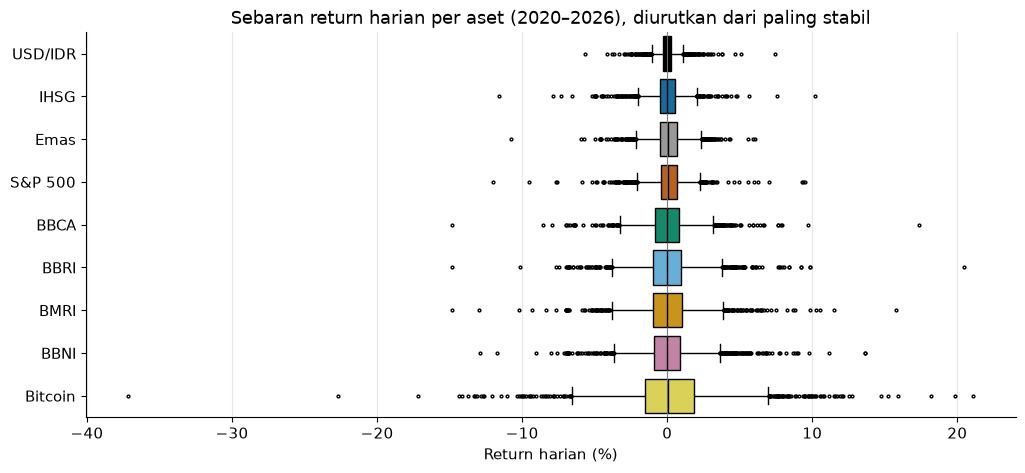

5 hari dengan return IHSG paling ekstrem:
[datetime.date(2026, 10, 16) datetime.date(2020, 3, 26)
 datetime.date(2025, 4, 8) datetime.date(2026, 6, 9)
 datetime.date(2026, 1, 28)]


In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
urutan = ret.std().sort_values().index
sns.boxplot(data=ret[urutan], orient="h", palette=[WARNA[a] for a in urutan],
            fliersize=2, linewidth=1, ax=ax)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Return harian (%)"); ax.set_ylabel("")
ax.set_title("Sebaran return harian per aset (2020–2026), diurutkan dari paling stabil")
simpan("00_boxplot_return")
plt.show()

# 5 hari paling ekstrem untuk IHSG
print("5 hari dengan return IHSG paling ekstrem:")
print(ret["IHSG"].abs().sort_values(ascending=False).head().index.date)

## 3. Visualisasi

> **Untuk semua anggota:** pakai variabel `close`, `volume`, `ret`, `norm`, `close_m` dari Bagian 2. Warna tiap aset pakai dict `WARNA[...]` supaya konsisten di semua grafik. Simpan grafik pakai `simpan("nama_file")` sebelum `plt.show()`. **Jangan ubah sel milik anggota lain.**

### 3.1 Line Plot
*(Raffa)*

Saran: pergerakan harga penutupan **IHSG** 2020–2026, beri anotasi pada peristiwa penting (mis. crash COVID Maret 2020).

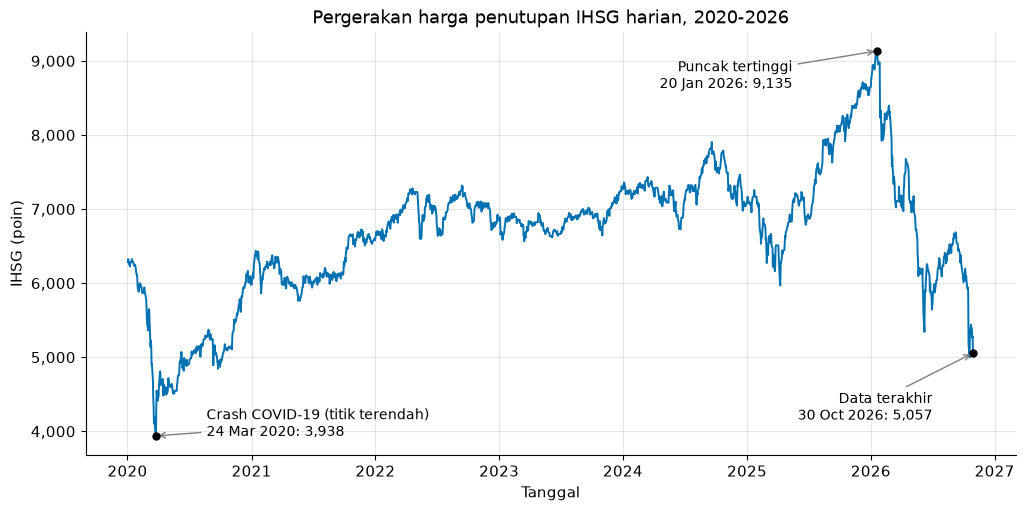

In [12]:
# Line Plot: harga penutupan IHSG 2020-2026 dengan anotasi titik penting
ihsg = close["IHSG"]
t_low, t_high, t_last = ihsg.idxmin(), ihsg.idxmax(), ihsg.index[-1]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(ihsg.index, ihsg, color=WARNA["IHSG"], lw=1.4)

def anotasi(tgl, teks, dx, dy, ha="left"):
    ax.annotate(f"{teks}\n{tgl:%d %b %Y}: {ihsg[tgl]:,.0f}", xy=(tgl, ihsg[tgl]),
                xytext=(tgl + pd.Timedelta(days=dx), ihsg[tgl] + dy), ha=ha,
                arrowprops=dict(arrowstyle="->", color="grey"), fontsize=10)
    ax.scatter([tgl], [ihsg[tgl]], color="black", zorder=5, s=25)

anotasi(t_low, "Crash COVID-19 (titik terendah)", 150, 0)
anotasi(t_high, "Puncak tertinggi", -250, -500, ha="right")
anotasi(t_last, "Data terakhir", -120, -900, ha="right")

ax.set_title("Pergerakan harga penutupan IHSG harian, 2020-2026")
ax.set_xlabel("Tanggal"); ax.set_ylabel("IHSG (poin)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
simpan("01_line_ihsg")
plt.show()

**Interpretasi:**

- **Crash COVID:** dari ~6.300 (awal 2020) ke 3.938 (24 Mar 2020), turun ~37% dalam 3 bulan.
- **Pulih pelan**, balik ke level sebelum COVID di awal 2021.
- **2022-2024** jalan di tempat, di kisaran 6.500-7.500.
- **Reli 2025:** naik terus dari April 2025 sampai puncak 9.135 (20 Jan 2026).
- **Koreksi 2026:** jatuh ke 5.057 (30 Okt 2026), turun ~45% dari puncak, lebih dalam dari COVID. Turunnya bertahap, sempat naik sebentar tapi tidak bertahan.
- **Intinya:** naik dalam jangka panjang, tapi kena 2 guncangan besar (2020 dan 2026).
- **Batasan:** grafik hanya menunjukkan pergerakan, bukan penyebab atau prediksi.

### 3.2 Area Plot
*(Raffa)*

Saran: **stacked area volume** transaksi 4 saham bank (BBCA, BBRI, BMRI, BBNI), mis. dirata-rata per bulan pakai `volume[[...]].resample("ME").sum()` agar tidak terlalu ramai.

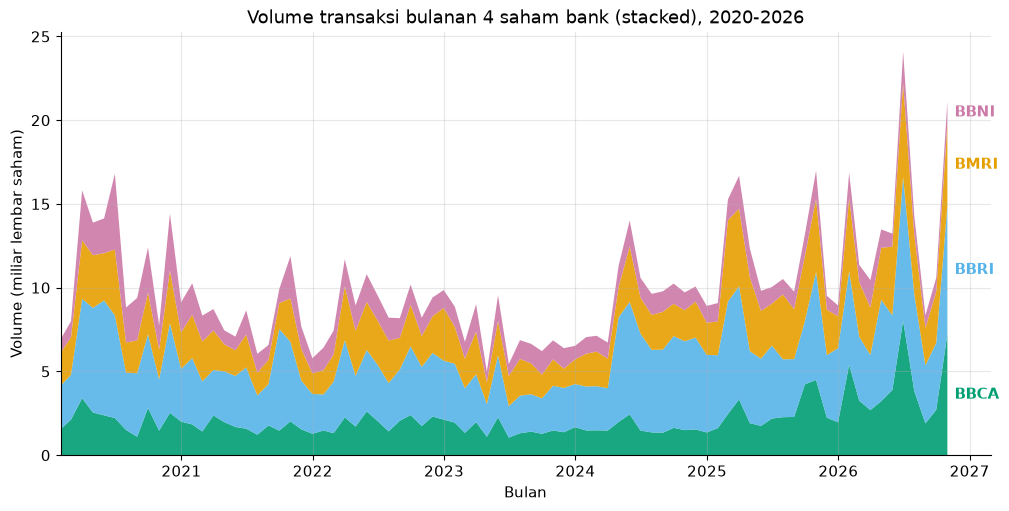

In [13]:
# Area Plot: stacked area volume bulanan 4 saham bank
bank = ["BBCA", "BBRI", "BMRI", "BBNI"]
vol_m = volume[bank].resample("ME").sum() / 1e9      # miliar lembar per bulan

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.stackplot(vol_m.index, vol_m.T, labels=bank,
             colors=[WARNA[b] for b in bank], alpha=0.9)
# direct labeling di ujung kanan (tanpa legend), posisi di tengah tiap lapisan
kum = vol_m.cumsum(axis=1).iloc[-1]
for b in bank:
    ax.text(vol_m.index[-1] + pd.Timedelta(days=20), kum[b] - vol_m[b].iloc[-1] / 2, b,
            color=WARNA[b], va="center", fontweight="bold")
ax.set_xlim(vol_m.index[0], vol_m.index[-1] + pd.Timedelta(days=120))
ax.set_title("Volume transaksi bulanan 4 saham bank (stacked), 2020-2026")
ax.set_xlabel("Bulan"); ax.set_ylabel("Volume (miliar lembar saham)")
simpan("02_area_volume_bank")
plt.show()

In [14]:
# Cek: volume (lembar) vs perkiraan nilai transaksi (harga x volume) per saham bank
# Catatan: harga close sudah adjusted, jadi nilai ini perkiraan kasar, bukan nilai transaksi resmi BEI.
nilai = (close[bank] * volume[bank]).sum() / 1e12      # triliun rupiah, total 2020-2026
porsi = pd.DataFrame({
    "rata-rata harga (Rp)": close[bank].mean(),
    "volume/bulan (miliar lembar)": vol_m.mean(),
    "porsi volume (%)": volume[bank].sum() / volume[bank].sum().sum() * 100,
    "porsi nilai (%)": nilai / nilai.sum() * 100,
})
porsi.round(1)

,rata-rata harga (Rp),volume/bulan (miliar lembar),porsi volume (%),porsi nilai (%)
Nama,,,,
BBCA,"7,008.30",2.20,21.60,36.10
BBRI,"3,306.50",4.00,40.00,31.70
BMRI,"3,572.70",2.50,24.90,21.90
BBNI,"3,299.20",1.40,13.60,10.30


**Interpretasi:**

- **Volume terbanyak:** BBRI (~4 miliar lembar/bulan), lalu BMRI, BBCA, BBNI.
- **Ini jumlah lembar, bukan rupiah.** Kalau dihitung dalam rupiah (tabel di atas), BBCA paling besar karena harganya ~2x lipat. BBRI tebal karena harganya murah, jadi banyak lembar pindah tangan.
- **Pertengahan 2020:** volume tinggi, pasar kacau karena pandemi.
- **2021-2023:** lebih sepi, terendah di April 2023.
- **Sejak 2024:** naik lagi, tertinggi Juni 2026 (~24 miliar lembar) saat IHSG turun. Mungkin karena banyak yang jual, tapi volume tidak bisa membedakan beli dan jual, jadi masih dugaan.
- **Kekurangan stacked area:** susah membandingkan satu saham antarwaktu, terutama BBNI yang ada di paling atas.

### 3.3 Multiple Time Series
*(Tristan)*

Saran: bandingkan `norm` (basis 100) beberapa aset lintas kategori, mis. IHSG, S&P 500, Bitcoin, Emas, USD/IDR. **Wajib direct labeling di ujung garis, tanpa legend.** Bitcoin naik jauh lebih tinggi, jadi pertimbangkan skala log (`ax.set_yscale("log")`).

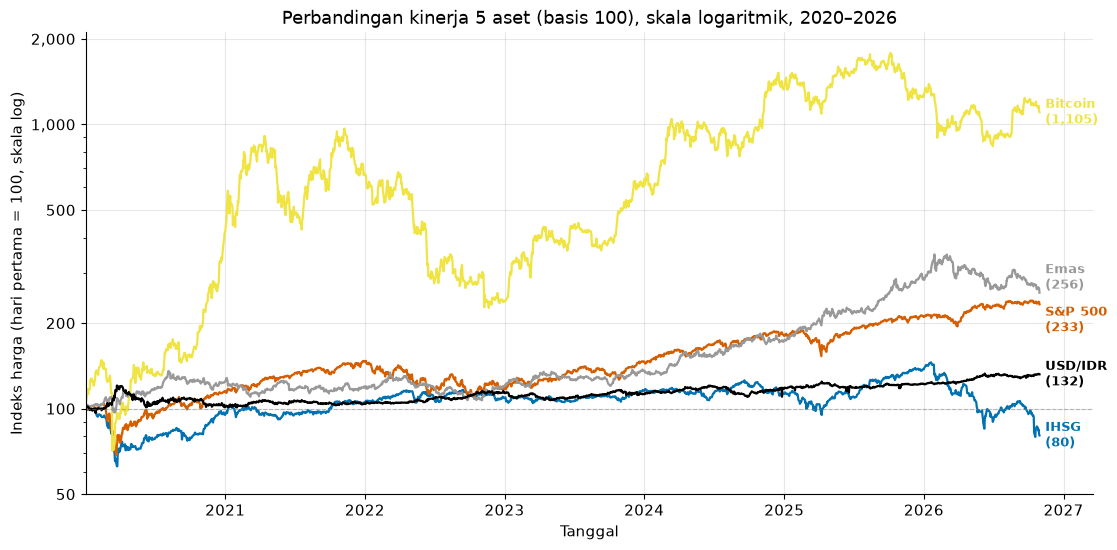

In [15]:
# Multiple Time Series: 5 aset lintas kategori, direct labeling, skala log
pilihan = ["IHSG", "S&P 500", "Bitcoin", "Emas", "USD/IDR"]

fig, ax = plt.subplots(figsize=(13, 6))

# Offset manual (faktor pengali di skala log) agar label tidak bertumpuk
label_offset = {"IHSG": 1.0, "S&P 500": 0.88, "Bitcoin": 1.0,
                "Emas": 1.13, "USD/IDR": 1.0}

for aset in pilihan:
    ax.plot(norm.index, norm[aset], color=WARNA[aset], lw=1.6)

    # Direct labeling di ujung kanan garis (tanpa legend)
    y_end = norm[aset].iloc[-1]
    y_label = y_end * label_offset[aset]
    ax.text(norm.index[-1] + pd.Timedelta(days=15), y_label,
            f"{aset}\n({y_end:,.0f})",
            color=WARNA[aset], va="center", fontsize=9, fontweight="bold")

ax.set_yscale("log")
ax.set_title("Perbandingan kinerja 5 aset (basis 100), skala logaritmik, 2020\u20132026")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Indeks harga (hari pertama = 100, skala log)")

# Tick khusus di skala log agar mudah dibaca
ax.set_yticks([50, 100, 200, 500, 1000, 2000])
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(norm.index[0], norm.index[-1] + pd.Timedelta(days=140))
ax.axhline(100, color="grey", ls="--", lw=0.8, alpha=0.5)   # garis basis 100

simpan("03_multi_timeseries")
plt.show()

**Interpretasi:**

- Grafik membandingkan 5 aset dari 5 kategori berbeda menggunakan **indeks basis 100** (hari pertama = 100) supaya bisa dibandingkan meskipun satuannya beda-beda. Skala logaritmik dipakai karena Bitcoin naik jauh lebih tinggi dari aset lain.

- **Bitcoin paling unggul:** dari 100 menjadi ±1.105 (naik ±11× lipat). Tapi pergerakannya paling liar — sempat turun tajam di 2022 (crash kripto) sebelum naik lagi.

- **Emas dan S&P 500 bersaing ketat:** emas di 256, S&P 500 di 233 (masing-masing naik ±150% dan ±133%). Keduanya naik relatif stabil, tapi S&P 500 lebih fluktuatif.

- **USD/IDR naik ke 132**, artinya rupiah melemah ±32% terhadap dolar. Pergerakannya paling tenang dari semua aset.

- **IHSG satu-satunya aset yang turun** (indeks 80, atau −20%). Setelah sempat pulih dan menyentuh puncak di awal 2026, IHSG jatuh tajam di 2026.

- **Kesimpulan visual:** investor Indonesia yang hanya pegang IHSG mendapat return negatif, sedangkan aset global (S&P 500, emas, Bitcoin) naik signifikan. Pelemahan rupiah memperburuk daya beli relatif.

- **Catatan:** skala log membuat perubahan persentase yang sama terlihat setinggi yang sama di mana pun di grafik, sehingga perbandingan lebih adil.

### 3.4 Seasonal Plot / Calendar Heatmap
*(Tristan)*

Saran: heatmap **rata-rata return bulanan IHSG** (sumbu Y = tahun, sumbu X = bulan) atau seasonal plot `close_m` per tahun. Return bisa positif/negatif → pakai skala warna **diverging** dengan titik tengah 0 (mis. `cmap="RdBu"`, `center=0`).

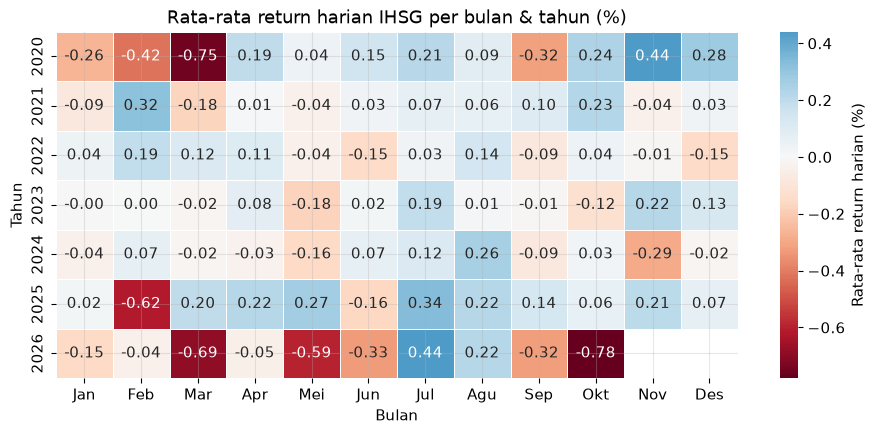

In [16]:
# Calendar Heatmap: rata-rata return harian IHSG per bulan & tahun
ret_ihsg = ret["IHSG"]
pivot = ret_ihsg.groupby([ret_ihsg.index.year, ret_ihsg.index.month]).mean().unstack()
pivot.index.name = "Tahun"
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
         "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
pivot.columns = BULAN[:pivot.shape[1]]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(pivot, cmap="RdBu", center=0, annot=True, fmt=".2f",
            linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Rata-rata return harian (%)"},
            ax=ax)
ax.set_title("Rata-rata return harian IHSG per bulan & tahun (%)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Tahun")

simpan("04_heatmap_return_ihsg")
plt.show()

**Interpretasi:**

- Heatmap menampilkan **rata-rata return harian IHSG (%)** untuk setiap kombinasi bulan dan tahun. Warna biru = positif (naik), merah = negatif (turun), makin gelap makin ekstrem.

- **Maret cenderung buruk:** merah di 5 dari 7 tahun. Maret 2020 (−0,75%) dan Maret 2026 (−0,69%) paling parah karena crash COVID dan koreksi 2026.

- **Juli dan Agustus cenderung positif:** biru di hampir semua tahun. Juli 2026 (+0,44%) adalah bulan terbaik 2026.

- **2026 didominasi merah**, terutama Mei (−0,59%), Juni (−0,33%), dan Oktober (−0,78%). Ini konsisten dengan tren turun IHSG yang terlihat di Line Plot.

- **2025 didominasi biru** (9 dari 12 bulan positif), kecuali Februari (−0,62%) dan Juni (−0,16%). Ini adalah periode reli IHSG.

- **Pola musiman tidak terlalu kuat:** tidak ada bulan yang selalu positif atau selalu negatif di semua tahun. Ini wajar karena pasar saham dipengaruhi banyak faktor fundamental dan sentimen, bukan hanya musim.

- **Catatan:** angka di heatmap adalah rata-rata return harian (bukan bulanan). Misalnya −0,75% per hari di Maret 2020 berarti rata-rata IHSG turun 0,75% setiap hari kerja di bulan itu.

## 4. Analisis Tren
*(Naufal Rafif)*

### 4.1 Moving Average
Saran: MA **20 hari** (± 1 bulan bursa) dan **200 hari** (± 1 tahun bursa) di atas harga asli IHSG. Jelaskan trade-off: window besar → kurva lebih halus, tapi NaN di awal lebih banyak dan lebih telat merespons perubahan.

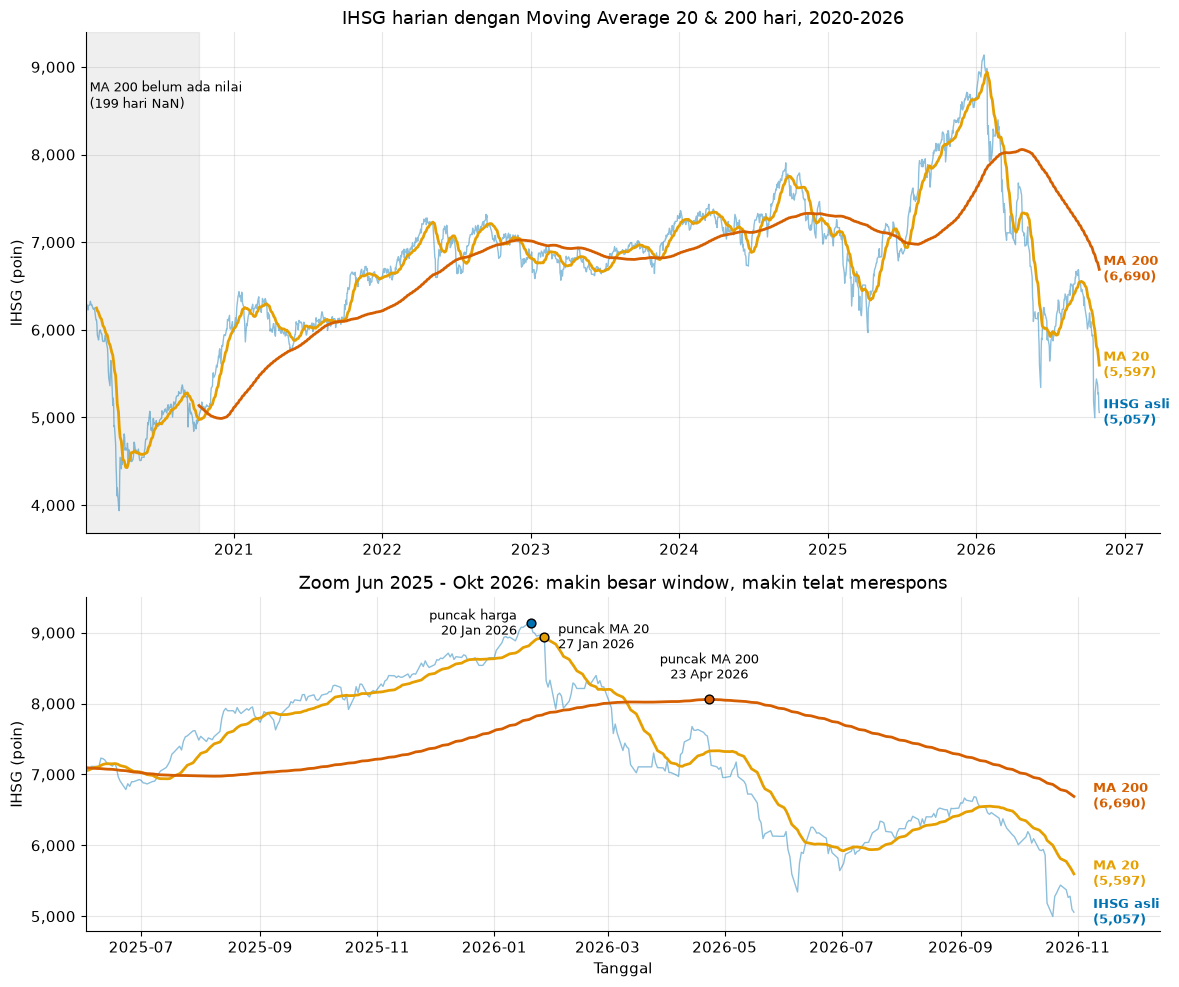

In [17]:
# Moving Average IHSG: window 20 hari (~1 bulan bursa) dan 200 hari (~1 tahun bursa)
ihsg = close["IHSG"]
WINDOW = {20: "#E69F00", 200: "#D55E00"}      # window -> warna (Okabe-Ito)
ma = pd.DataFrame({w: ihsg.rolling(window=w).mean() for w in WINDOW})

def plot_ma(ax, mulai=None):
    harga, rata = ihsg[mulai:], ma[mulai:]
    ax.plot(harga.index, harga, color=WARNA["IHSG"], lw=1, alpha=0.45)
    for w, warna in WINDOW.items():
        ax.plot(rata.index, rata[w], color=warna, lw=2)
    # direct labeling di ujung kanan garis (tanpa legend)
    ujung = harga.index[-1] + pd.Timedelta(days=10)
    ax.text(ujung, harga.iloc[-1], f"IHSG asli\n({harga.iloc[-1]:,.0f})", color=WARNA["IHSG"],
            va="center", fontsize=9, fontweight="bold")
    for w, warna in WINDOW.items():
        ax.text(ujung, rata[w].iloc[-1], f"MA {w}\n({rata[w].iloc[-1]:,.0f})", color=warna,
                va="center", fontsize=9, fontweight="bold")
    ax.set_ylabel("IHSG (poin)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={"height_ratios": [3, 2]})

# Panel atas: seluruh periode + daerah NaN MA 200 di awal data
plot_ma(ax1)
awal_ma200 = ma[200].first_valid_index()
ax1.axvspan(ihsg.index[0], awal_ma200, color="grey", alpha=0.12)
ax1.text(ihsg.index[0] + pd.Timedelta(days=10), ihsg.max() * 0.97,
         f"MA 200 belum ada nilai\n({ma[200].isna().sum()} hari NaN)", fontsize=9, va="top")
ax1.set_xlim(ihsg.index[0], ihsg.index[-1] + pd.Timedelta(days=150))
ax1.set_title("IHSG harian dengan Moving Average 20 & 200 hari, 2020-2026")

# Panel bawah: zoom puncak 2026 -> terlihat seberapa telat tiap MA mencapai puncaknya
ZOOM = "2025-06"
plot_ma(ax2, ZOOM)
posisi_label = {"harga": (-10, 0, "right"), "MA 20": (10, 0, "left"), "MA 200": (0, 12, "center")}
for seri, warna, nama in [(ihsg, WARNA["IHSG"], "harga"), (ma[20], WINDOW[20], "MA 20"),
                          (ma[200], WINDOW[200], "MA 200")]:
    t = seri[ZOOM:].idxmax()
    dx, dy, ha = posisi_label[nama]
    ax2.scatter([t], [seri[t]], color=warna, edgecolor="black", zorder=5, s=40)
    ax2.annotate(f"puncak {nama}\n{t:%d %b %Y}", xy=(t, seri[t]), xytext=(dx, dy),
                 textcoords="offset points", fontsize=9, ha=ha, va="bottom" if dy else "center")
ax2.set_xlim(ihsg[ZOOM:].index[0], ihsg.index[-1] + pd.Timedelta(days=45))
ax2.set_ylim(top=ihsg[ZOOM:].max() * 1.04)
ax2.set_title("Zoom Jun 2025 - Okt 2026: makin besar window, makin telat merespons")
ax2.set_xlabel("Tanggal")

fig.tight_layout()
simpan("05_moving_average_ihsg")
plt.show()

In [18]:
# Ringkasan trade-off window: NaN di awal vs kehalusan vs keterlambatan
seri_ma = {"IHSG asli": ihsg, "MA 20": ma[20], "MA 200": ma[200]}
t_puncak = ihsg[ZOOM:].idxmax()

trade_off = pd.DataFrame({
    "NaN di awal": {k: int(s.isna().sum()) for k, s in seri_ma.items()},
    "mulai ada nilai": {k: s.first_valid_index().date() for k, s in seri_ma.items()},
    # makin kecil std perubahan harian -> kurva makin halus
    "std perubahan harian (poin)": {k: s.diff().std() for k, s in seri_ma.items()},
    "puncak 2025-2026": {k: s[ZOOM:].idxmax().date() for k, s in seri_ma.items()},
    "telat dari puncak harga (hari bursa)": {
        k: ihsg.index.get_loc(s[ZOOM:].idxmax()) - ihsg.index.get_loc(t_puncak)
        for k, s in seri_ma.items()},
})

# Persilangan MA 20 vs MA 200 (golden cross = MA 20 naik melewati MA 200, death cross = sebaliknya)
posisi = np.sign(ma[20] - ma[200]).dropna()
silang = posisi[posisi.diff() != 0].iloc[1:]
terakhir = silang.index[-1]
print(f"Jumlah persilangan MA 20 & MA 200: {len(silang)}")
print(f"Persilangan terakhir: {terakhir:%d %b %Y} "
      f"({'golden cross' if silang.iloc[-1] > 0 else 'death cross'})")
trade_off

Jumlah persilangan MA 20 & MA 200: 18
Persilangan terakhir: 11 Mar 2026 (death cross)


,NaN di awal,mulai ada nilai,std perubahan harian (poin),puncak 2025-2026,telat dari puncak harga (hari bursa)
IHSG asli,0,2020-01-02,73.09,2026-01-20,0
MA 20,19,2020-01-29,17.52,2026-01-27,5
MA 200,199,2020-10-07,4.88,2026-04-23,67


**Interpretasi Moving Average:**

- **Pilihan window:** MA 20 hari (~1 bulan bursa) untuk tren jangka pendek, MA 200 hari (~1 tahun bursa) untuk tren jangka panjang. Keduanya pakai `rolling(window).mean()` biasa (tidak `center=True`), jadi tiap titik hanya memakai data masa lalu, seperti yang bisa dilihat investor pada hari itu.
- **Trade-off 1, NaN di awal:** MA 20 kosong 19 hari pertama (baru ada sejak 29 Jan 2020), MA 200 kosong 199 hari (baru ada sejak 7 Okt 2020, daerah abu-abu). Akibatnya **crash COVID Maret 2020 sama sekali tidak tercatat di MA 200**. NaN bisa dihindari dengan `min_periods`, tapi nilai awalnya hanya dihitung dari sedikit data jadi kurang bisa dipercaya.
- **Trade-off 2, kehalusan:** perubahan harian IHSG asli rata-rata bergerak ±73 poin (std), MA 20 ±18 poin, MA 200 hanya ±5 poin. Makin besar window, noise harian makin hilang dan tren besarnya makin jelas.
- **Trade-off 3, keterlambatan (lag):** harga IHSG memuncak 20 Jan 2026 (9.135). MA 20 memuncak 5 hari bursa kemudian (27 Jan), sedangkan MA 200 baru memuncak 23 Apr 2026, sekitar 3 bulan kemudian, saat harga sudah turun jauh. Window besar halus, tetapi telat memberi sinyal.
- **Sinyal tren:** MA 20 memotong MA 200 dari atas ke bawah (*death cross*) pada 11 Mar 2026 dan bertahan di bawahnya sampai akhir data. Pada 30 Okt 2026 urutannya harga (5.057) < MA 20 (5.597) < MA 200 (6.690), artinya tren jangka pendek dan panjang sama-sama turun.
- **Pola 2021-2025:** dari 18 persilangan MA 20 & MA 200, 16 terjadi pada 2021-2025 (11 di antaranya pada 2022-2024). Seringnya persilangan menandakan pasar *sideways* (jalan di tempat), sesuai dengan kisaran 6.500-7.500 di Line Plot. Jadi sinyal *golden/death cross* baru berarti kalau trennya bertahan lama, seperti tahun 2026.

### 4.2 Fitting Model
Saran: `numpy.polyfit` linear & polynomial pada IHSG, atau fit eksponensial (`polyfit` pada `log(harga)`) untuk Bitcoin/Emas. Sumbu x pakai angka hari ke-n, bukan tanggal.

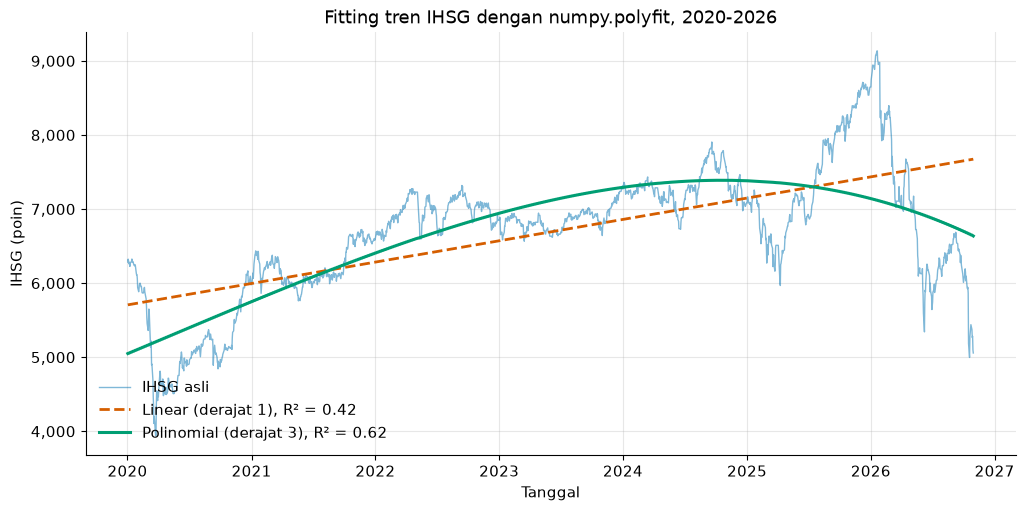

Linear: IHSG = 1.107 * hari + 5,707  -> rata-rata naik ~288 poin/tahun
Nilai di hari terakhir: asli 5,057 | linear 7,674 | polinomial 6,637


In [19]:
# Fitting model IHSG: linear (derajat 1) & polinomial (derajat 3) dengan numpy.polyfit
x = np.arange(len(ihsg))     # sumbu x = hari bursa ke-n (0, 1, 2, ...), bukan tanggal
y = ihsg.values

def r_kuadrat(y_asli, y_fit):
    return 1 - ((y_asli - y_fit) ** 2).sum() / ((y_asli - y_asli.mean()) ** 2).sum()

koef_lin = np.polyfit(x, y, deg=1)      # [kemiringan, intersep]
koef_pol = np.polyfit(x, y, deg=3)
fit_lin = np.polyval(koef_lin, x)
fit_pol = np.polyval(koef_pol, x)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(ihsg.index, y, color=WARNA["IHSG"], lw=1, alpha=0.5, label="IHSG asli")
ax.plot(ihsg.index, fit_lin, color="#D55E00", lw=2, ls="--",
        label=f"Linear (derajat 1), R² = {r_kuadrat(y, fit_lin):.2f}")
ax.plot(ihsg.index, fit_pol, color="#009E73", lw=2.2,
        label=f"Polinomial (derajat 3), R² = {r_kuadrat(y, fit_pol):.2f}")
ax.set_title("Fitting tren IHSG dengan numpy.polyfit, 2020-2026")
ax.set_xlabel("Tanggal"); ax.set_ylabel("IHSG (poin)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="lower left", frameon=False)
simpan("06_fitting_ihsg")
plt.show()

HARI_PER_TAHUN = 260     # data hanya hari kerja: 52 minggu x 5 hari
print(f"Linear: IHSG = {koef_lin[0]:.3f} * hari + {koef_lin[1]:,.0f}"
      f"  -> rata-rata naik ~{koef_lin[0] * HARI_PER_TAHUN:,.0f} poin/tahun")
print(f"Nilai di hari terakhir: asli {y[-1]:,.0f} | linear {fit_lin[-1]:,.0f} | polinomial {fit_pol[-1]:,.0f}")

In [20]:
# Kenapa derajat 3? Bandingkan R² dan RMSE untuk derajat 1-6
banding = []
for d in range(1, 7):
    y_fit = np.polyval(np.polyfit(x, y, deg=d), x)
    banding.append({"derajat": d, "R²": r_kuadrat(y, y_fit),
                    "RMSE (poin)": np.sqrt(((y - y_fit) ** 2).mean()),
                    "fit hari terakhir": y_fit[-1]})
pd.DataFrame(banding).set_index("derajat").round(3)

,R²,RMSE (poin),fit hari terakhir
derajat,,,
1,0.42,665.69,"7,673.80"
2,0.61,546.98,"6,826.80"
3,0.62,542.20,"6,636.71"
4,0.64,524.64,"6,228.38"
5,0.76,431.97,"5,249.17"
6,0.76,431.70,"5,303.64"


#### Fitting eksponensial (Emas & Bitcoin)
Harga aset yang tumbuh dengan persentase kurang lebih tetap per tahun mengikuti model eksponensial $harga = a \cdot e^{b \cdot x}$. Jika kedua sisi di-log, modelnya menjadi linear: $\log(harga) = \log(a) + b \cdot x$, sehingga cukup pakai `np.polyfit(x, np.log(harga), 1)`. Pertumbuhan per tahun $= e^{b \cdot 260} - 1$ (260 hari bursa per tahun). Grafik memakai skala log, jadi kurva eksponensial tampak sebagai garis lurus.

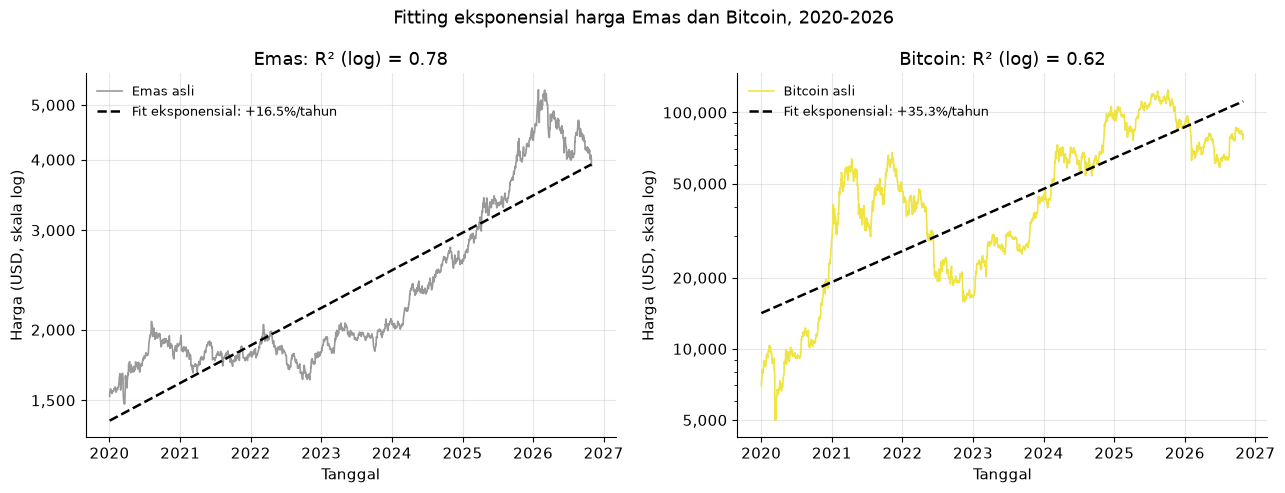

,pertumbuhan/tahun (%),R² (skala log),harga asli terakhir,fit hari terakhir
Emas,16.52,0.78,"3,898.90","3,925.88"
Bitcoin,35.25,0.62,"77,198.21","111,555.78"


In [21]:
# Fitting eksponensial: polyfit derajat 1 pada log(harga)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hasil_exp = {}
TICK_Y = {"Emas": [1500, 2000, 3000, 4000, 5000], "Bitcoin": [5000, 10000, 20000, 50000, 100000]}
for ax, aset in zip(axes, TICK_Y):
    y_aset = close[aset].values
    b, log_a = np.polyfit(x, np.log(y_aset), deg=1)
    fit = np.exp(log_a + b * x)
    hasil_exp[aset] = {
        "pertumbuhan/tahun (%)": (np.exp(b * HARI_PER_TAHUN) - 1) * 100,
        "R² (skala log)": r_kuadrat(np.log(y_aset), np.log(fit)),
        "harga asli terakhir": y_aset[-1],
        "fit hari terakhir": fit[-1],
    }
    ax.plot(close.index, y_aset, color=WARNA[aset], lw=1.2, label=f"{aset} asli")
    ax.plot(close.index, fit, color="black", lw=1.8, ls="--",
            label=f"Fit eksponensial: +{hasil_exp[aset]['pertumbuhan/tahun (%)']:.1f}%/tahun")
    ax.set_yscale("log")
    ax.set_yticks(TICK_Y[aset])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"{aset}: R² (log) = {hasil_exp[aset]['R² (skala log)']:.2f}")
    ax.set_xlabel("Tanggal"); ax.set_ylabel("Harga (USD, skala log)")
    ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.suptitle("Fitting eksponensial harga Emas dan Bitcoin, 2020-2026")
fig.tight_layout()
simpan("07_fitting_eksponensial")
plt.show()

pd.DataFrame(hasil_exp).T.round(2)

**Interpretasi Fitting Model:**

- **Linear (derajat 1):** kemiringan +1,11 poin per hari bursa, atau rata-rata naik ±288 poin/tahun. Tapi R² hanya 0,42 dan nilai fit di hari terakhir (±7.674) jauh di atas harga asli (5.057). Garis lurus tidak bisa menangkap crash 2020, reli 2025, dan koreksi 2026.
- **Polinomial (derajat 3):** R² naik ke 0,62, kurva menangkap bentuk besar "turun-naik-mendatar-turun". Derajat 3 dipilih karena dari tabel, naik dari derajat 2 ke 4 hanya menambah R² sedikit (0,61 → 0,64). Derajat 5-6 memang R²-nya ±0,76, tapi kurvanya mulai mengikuti guncangan sesaat (overfitting) dan bentuk polinomial derajat tinggi berubah tajam di ujung data, jadi berbahaya kalau dipakai untuk melihat arah ke depan.
- **Eksponensial Emas:** rata-rata tumbuh ±16,5% per tahun dengan R² (log) 0,78, jauh lebih cocok daripada model mana pun untuk IHSG. Tapi grafiknya menunjukkan emas tidak tumbuh dengan laju tetap: di atas garis fit pada 2020-2021, di bawahnya pada 2022-2024 saat harga cenderung datar, lalu naik jauh lebih cepat dan berada di atas garis pada 2025-2026. Nilai fit hari terakhir (±3.926 USD) yang dekat dengan harga asli (3.899 USD) hanya kebetulan karena emas sedang turun di Oktober 2026.
- **Eksponensial Bitcoin:** rata-rata tumbuh ±35% per tahun, tapi R² (log) hanya 0,62. Harga akhir (±77.198 USD) jauh di bawah garis fit (±111.556 USD) karena Bitcoin bergerak dalam siklus naik-crash yang besar (mis. crash 2022), bukan tumbuh mulus.
- **Kesimpulan & batasan:** IHSG tidak punya tren tunggal yang jelas sepanjang 2020-2026 (R² rendah untuk semua model sederhana), berbeda dengan Emas yang trennya kuat. Fitting di sini hanya **merangkum pola masa lalu**, bukan prediksi; ekstrapolasi polinomial ke luar periode data tidak bisa dipercaya.

## 5. Kesimpulan
*(Naufal Ramadhan)*

### 5.1 Insight utama
1. **IHSG satu-satunya aset yang merugi.** Selama 2020–2026 IHSG turun ±19,5% (indeks basis 100 → 80) dan mengalami dua guncangan besar: crash COVID (turun ±37% ke 3.938 pada 24 Mar 2020) dan koreksi 2026 (turun ±45% dari puncak 9.135 pada 20 Jan 2026 ke 5.057 pada 30 Okt 2026). Koreksi 2026 lebih dalam daripada crash COVID.
2. **Aset global jauh mengungguli IHSG, tetapi dengan risiko berbeda.** Bitcoin naik ±11× lipat (+1.005%) namun paling volatil (std return 3,70% per hari, >3× IHSG, return harian terburuk −37%). Emas (+156%) dan S&P 500 (+133%) naik lebih stabil. Ini menggambarkan *trade-off* risiko vs imbal hasil.
3. **Rupiah melemah ±32% terhadap dolar AS** (±13.700 → ±18.070), dengan pergerakan paling tenang (std 0,71% per hari). Bagi investor yang hanya memegang IHSG, kerugian dalam dolar menjadi lebih besar karena pelemahan rupiah.
4. **Volume saham bank naik saat pasar tertekan.** BBRI paling banyak diperdagangkan dalam jumlah lembar, tetapi BBCA terbesar dalam nilai rupiah. Volume tinggi pada pertengahan 2020, sepi pada 2021–2023, lalu mencapai puncak Juni 2026 (±24 miliar lembar) saat IHSG sedang turun.
5. **Pola musiman IHSG ada, tetapi lemah.** Maret cenderung negatif (merah di 5 dari 7 tahun), Juli–Agustus cenderung positif. Namun tidak ada bulan yang selalu naik atau selalu turun, jadi pola musiman tidak bisa dijadikan dasar keputusan tunggal.
6. **Moving Average menegaskan tren turun 2026.** *Death cross* MA 20 & MA 200 terjadi pada 11 Mar 2026 dan bertahan sampai akhir data (harga 5.057 < MA 20 5.597 < MA 200 6.690). Sebaliknya, 16 dari 18 persilangan terjadi pada 2021–2025, tanda pasar *sideways*. MA 200 terlambat ±3 bulan menandai puncak harga.
7. **IHSG tidak memiliki tren tunggal, Emas memiliki tren eksponensial yang kuat.** Fitting linear IHSG hanya R² 0,42 dan polinomial derajat 3 R² 0,62, sedangkan fitting eksponensial Emas R² (log) 0,78 dengan pertumbuhan ±16,5% per tahun. Bitcoin tumbuh ±35% per tahun tetapi fit-nya buruk (R² 0,62) karena bergerak dalam siklus naik–crash.
8. **Return semua aset memiliki *fat tails*** (kurtosis 5–15): sebagian besar hari bergerak kecil, tetapi sesekali terjadi lonjakan ekstrem. Outlier tidak dibuang karena merupakan peristiwa pasar nyata.

### 5.2 Kendala
- **Kalender perdagangan berbeda-beda** (Bitcoin 7 hari, BEI mengikuti libur nasional Indonesia, S&P 500 & Emas mengikuti libur AS). Data harus diseragamkan ke hari kerja dan hari libur diisi *forward fill*, sehingga data Bitcoin akhir pekan tidak terpakai.
- **Skala dan satuan aset sangat berbeda** (poin, IDR, USD), sehingga perbandingan langsung tidak mungkin. Solusinya normalisasi basis 100 dan skala logaritmik.
- **Keterbatasan data volume:** kurs USD/IDR tidak memiliki volume, dan volume saham dalam lembar (bukan rupiah) sehingga menyesatkan bila dibandingkan antarsaham tanpa dikalikan harga.
- **Trade-off Moving Average:** MA 200 kosong (NaN) 199 hari pertama sehingga crash COVID tidak tercatat, dan responsnya terlambat.
- **Fitting polinomial derajat tinggi cenderung *overfitting*** dan tidak dapat dipakai untuk ekstrapolasi.
- **Sumber data `yfinance` adalah API tidak resmi** yang bisa berubah; karena itu data disimpan ke CSV agar hasil notebook *reproducible*.

### 5.3 Rencana pengembangan
- **Dekomposisi time series** (mis. STL / `seasonal_decompose`) untuk memisahkan tren, musiman, dan residual secara formal.
- **Korelasi bergulir (*rolling correlation*)** antaraset, misalnya IHSG vs USD/IDR dan IHSG vs S&P 500, serta konversi IHSG ke dolar AS.
- **Visualisasi volatilitas dan *drawdown*** (rolling standard deviation, kedalaman penurunan dari puncak) untuk mengukur risiko secara visual.
- **Dashboard interaktif** (mis. Plotly/Streamlit) agar pengguna dapat memilih aset dan periode sendiri.
- **Model peramalan** (ARIMA/Prophet) dengan evaluasi *out-of-sample*, serta penambahan data makro (suku bunga BI, inflasi) untuk menjelaskan penyebab pergerakan.

## 6. Deklarasi Penggunaan AI
*(Naufal Ramadhan — rekap dari file log di folder Log/)*

Kami menyatakan dengan sebenar-benarnya bahwa dalam pengerjaan tugas Midterm Project ini kami menggunakan bantuan AI generatif sebagaimana dirinci pada tabel berikut. Seluruh hasil kode, interpretasi data, draf laporan, dan slide telah kami telaah, pahami, verifikasi, dan sesuaikan secara mandiri, dan kami bertanggung jawab penuh atas integritas akademik tugas ini. Bukti prompt dan percakapan tersimpan lengkap di folder Log/ (file log_ai_<nama>.md dan Screenshot_AI_<NIM>.pdf), serta file rekap resmi laporan/Deklarasi_AI_Kelompok_Cihuy.pdf.

### 6.1 Tabel Rekapitulasi Penggunaan AI Keseluruhan Anggota

| No | Anggota & NIM | Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Ketergantungan |
|:--:|:--------------|:---------|:--------------------|:-------------------------------|:--------------:|
| 1 | **Davu**<br>103012340479 | Claude (Claude Code) | Perencanaan proyek | Membaca soal, membagi jobdesk 5 anggota, membuat struktur folder & README | Sedang |
| 2 | **Davu**<br>103012340479 | Claude (Claude Code) | Dataset & kerangka notebook | Script unduh data Yahoo Finance (download_data.py), cleaning, data profiling, kerangka notebook, draf laporan Bab 1–2 | Tinggi |
| 3 | **Raffa**<br>103012300163 | Claude (Claude Code) | Line Plot & Area Plot (3.1–3.2) | Menulis kode Line Plot IHSG dan Area Plot volume saham bank, sel verifikasi nilai rupiah vs lembar saham, draf interpretasi, penjelasan kode | Tinggi |
| 4 | **Tristan**<br>103012300253 | Antigravity (Google DeepMind) | Multiple Time Series & Calendar Heatmap (3.3–3.4) | Menulis kode Multiple Time Series (direct labeling, basis 100, skala log) dan Calendar Heatmap return harian IHSG (skala divergen), beserta interpretasi | Tinggi |
| 5 | **Naufal Rafif**<br>103012300403 | Claude (Claude Code) | Analisis Tren (4.1–4.2) | Menulis kode Moving Average (20 & 200 hari), tabel trade-off window, fitting 
umpy.polyfit linear, polinomial derajat 3, dan eksponensial Emas & Bitcoin, draf interpretasi | Tinggi |
| 6 | **Naufal Ramadhan**<br>103012300239 | Antigravity (Google DeepMind) | Kesimpulan, Deklarasi AI, Daftar Pustaka, draf awal laporan & slide | Clone repo, menyusun draf kesimpulan (8 insight, 6 kendala, 5 pengembangan), merekap deklarasi AI, melengkapi sitasi pustaka formal, membuat draf laporan PDF awal (5 hal) dan slide awal (10 slide) | Tinggi |
| 7 | **Naufal Ramadhan**<br>103012300239 | Google Gemini (Gemini Web) | Parafrase & revisi narasi laporan (Bab 1–5) | Mengubah bahasa draf laporan agar mengalir alami layaknya tulisan mahasiswa/praktisi data, tidak kaku, dan meminimalkan pola khas AI untuk dokumen Word/PDF final 11 halaman | Sedang |
| 8 | **Naufal Ramadhan**<br>103012300239 | Antigravity (Google DeepMind) | Pembaruan Slide (PPTX & PDF) & Sinkronisasi Dokumen | Menyelaraskan seluruh 10 slide dengan laporan final hasil editan (Bab 1–5, logo Telkom, peran anggota, 8 insight 2-kolom, kendala & pengembangan) serta finalisasi log AI | Sedang |

### 6.2 Rekap Prompt Utama & Bukti Screenshot per Anggota

| Anggota & Peran | Prompt Utama yang Digunakan (Dikutip dari Log) | File Bukti Screenshot di Log/ |
|:----------------|:-----------------------------------------------|:--------------------------------|
| **Adhyatma Chrysostomos Davu**<br>103012340479<br>*Koordinator & Data* | • *kamu baca dulu kita disuruh apa di pdf itu. kelompokku ada 5 orang dan tolong bagi2 jobdesknya...*<br>• *Kelompok cihuy / topik : Pasar Saham & Keuangan / sumber dataset : https://finance.yahoo.com / Pakai semua dataset yang ada dari situ*<br>• *lakukan jobdeskku sekarang* | Screenshot_AI_103012340479.pdf (hal. 1–9) |
| **Raffa Anung El Haqqi**<br>103012300163<br>*Line & Area Plot* | • *sekarang saya raffa baca readme yang ada dulu dan pahami*<br>• *oke sekarang saya harus ngapain dan gimana bantuin dulu ... bantu saya memahami dong*<br>• *coba sekarang interpretasi mu gimana setiap hasil tadi ... buatkan drafnya dan untuk interpretasinya kirim sini dulu saya mau pahami* | Screenshot_AI_103012300163.pdf (hal. 1–8) |
| **Tristan Satria Perdana Hermawan**<br>103012300253<br>*Multi Series & Heatmap* | • *pelajari folder Visdat-Cihuy ini, baca juga README nya*<br>• *lanjutkan pengerjaan Bagian 3.3 dan 3.4, sesuaikan dengan pengerjaan teman teman saya seperti pembuatan log_ai nya dll* | Screenshot_AI_103012300253.pdf (hal. 1–5) |
| **Naufal Rafif Hidayat**<br>103012300403<br>*Analisis Tren (MA & Fit)* | • *clone github ini https://github.com/davuchrys/Visdat-Cihuy.git kemudian kerjakan sesuai readme nya*<br>• (Instalasi paket, implementasi MA 20 & 200, tabel trade-off, fitting polinomial & eksponensial) | Screenshot_AI_103012300403.pdf (hal. 1–6) |
| **Ahmad Naufal Ramadhan**<br>103012300239<br>*Kesimpulan, Laporan, Slide* | • *pelajari folder visdat-cihuy ini ... kerjakan 1. Notebook Bagian 5 (Kesimpulan) ... s.d. 6. Rekap Log AI*<br>• (Lampiran draf PDF) *ubah laporan tersebut agar terlihat natural*<br>• *perbarui lagi slide presentasinya menyesuaikan dengan laporan yang telah saya buat*<br>• *tambahkan percakapan kita sekarang ini dan percakapan di ss.pdf ke dalam log_ai NaufalRamadhan.md* | Screenshot_AI_103012300239.pdf (hal. 1–7 & IDE Log) |

*Rincian interaksi setiap sesi tersimpan di folder Log/ (log_ai_Davu.md, log_ai_Raffa.md, log_ai_Tristan.md, log_ai_NaufalRafif.md, dan log_ai_NaufalRamadhan.md). Dokumen formal bertanda tangan tersedia di laporan/Deklarasi_AI_Kelompok_Cihuy.pdf.*

## 7. Daftar Pustaka

1. Yahoo Finance. (2026). *Historical prices: ^JKSE, ^GSPC, BBCA.JK, BBRI.JK, BMRI.JK, BBNI.JK, BTC-USD, GC=F, IDR=X*. Diakses 2 November 2026, dari https://finance.yahoo.com
2. Aroussi, R. (2026). *yfinance: Download market data from Yahoo! Finance's API* [Python library]. https://github.com/ranaroussi/yfinance
3. Wilke, C. O. (2019). *Fundamentals of Data Visualization*. O'Reilly Media. https://clauswilke.com/dataviz/
4. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
5. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a
6. Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2
7. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
8. Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
9. Okabe, M., & Ito, K. (2008). *Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people*. https://jfly.uni-koeln.de/color/
10. Materi Perkuliahan Visualisasi Data (CAK4XBB3), Minggu 1–6 (time series, line/area plot, multiple time series, seasonal plot & heatmap, moving average & fitting).